# 15. Graph machine learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/15_ml.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/15_ml.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-15.svg" alt="duckOSM notebook manual, chapter 15: Graph machine learning" width="100%">

| **You learn** | the junction graph and the turn graph; networkx and rustworkx graphs; the feature arrays; a PyTorch Geometric graph; a small graph neural network that learns the speed limits; how a prediction goes back to its edge |
|---|---|
| **Time** | about 4 minutes (the install of PyTorch included) |
| **Extras** | `duckosm[ml,graph,viz]` (the install cell installs them) |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[ml,graph,viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## Two graphs of one road network

A road network is a graph, but there are two ways to make it one. Each way answers other questions, and duckOSM gives
both.

- The **junction graph** (`graph="nodes"`): a node is a junction, and an arc is an edge, one direction of a road. This
  is the graph of OSMnx and of most map tools. Use it when the question is about places: which junctions are central,
  how the streets connect.
- The **turn graph** (`graph="turns"`): a node is an edge, and an arc is a legal turn from one edge to the next. This
  is the routing graph of duckOSM (`<mode>.edge_graph`). A forbidden turn has no arc. Use it when the question is about
  roads: a value for each road (a speed, a flow, a class), or a route that obeys the turn rules.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/ml-two-graphs.svg" alt="The junction graph: junctions joined by edges. The turn graph: edges joined by turns" width="100%">

| Graph | A node is | An arc is | Node features | Arc features |
|---|---|---|---|---|
| `graph="nodes"` | a junction | an edge | `lon`, `lat` | the `features` columns of the edge |
| `graph="turns"` | an edge | a legal turn | the `features` columns of the edge | `cost`: the seconds of the first edge |

The module `duckosm.ml` makes these graphs for five libraries:

| Call | Library | Graph |
|---|---|---|
| `to_networkx` | networkx | the turn graph, a `DiGraph` |
| `to_networkx_nodes` | networkx | the junction graph, a `MultiDiGraph` (as OSMnx) |
| `to_rustworkx` | rustworkx | either graph, a `PyDiGraph` |
| `graph_arrays` | numpy | the index and feature arrays, for any library |
| `to_pyg` | PyTorch Geometric | either graph, a `Data` object |
| `to_dgl` | DGL | either graph, a `DGLGraph` |

DuckDB makes the index arrays of each graph in SQL. Python only puts them into the objects of the library.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> Each graph keeps the `edge_id`. A model predicts a value for each node or arc, and the `edge_id` takes each value back to its road. Then the value joins to the network, to a map and to your own data (chapter 4).

## Build Monaco

The graphs of this chapter use the driving network. The build is the same as in chapter 1.

In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
net                                                   # the card

cut: 34461 nodes, 5685 ways, 339 relations

Output: ~/.cache/duckosm/work/monaco-20261120-193841-4882/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The driving network of Monaco has 2840 edges. Each edge is one node of the turn graph and one arc of the junction graph.

## networkx

[networkx](https://networkx.org) is the common graph library of Python. It has hundreds of algorithms: shortest paths,
centrality, components, communities. It keeps the graph in Python objects, so it is slow on large areas, but it is the
fastest way to try an idea on a city.

### The turn graph: `to_networkx`

`net.driving.to_networkx()` is the same as `duckosm.ml.to_networkx(net.driving)`. It gives a `networkx.DiGraph`. A node
is an `edge_id` and carries the data of its road: `name`, `highway`, `length_m`, `maxspeed_kmh`, `cost_s` and
`geometry` (WKT). An arc is a legal turn. Its `weight` is the cost of the first edge:

| `weight` | The weight of an arc |
|---|---|
| `"time"` (default) | the travel time of the first edge, in seconds (`cost_s`) |
| `"length"` | the length of the first edge, in metres (`length_m`) |

In [3]:
import networkx as nx                                     # the graph library

g = net.driving.to_networkx()                              # the turn graph: a node is an edge_id
first = next(iter(g.nodes))                                # one edge
g.number_of_nodes(), g.number_of_edges(), first, g.nodes[first]["highway"], list(g.out_edges(first, data=True))

(2840,
 5082,
 414242052250797,
 'residential',
 [(414242052250797, 4950030941241418106, {'weight': 5.308905124664307}),
  (414242052250797, 8638126748304063112, {'weight': 5.308905124664307})])

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The turn graph has 2840 nodes, one for each edge, and 5082 arcs, one for each legal turn. The first edge has two turns. Both arcs have the same weight (5.3 s), because the weight is the time of the first edge.

### A route in the turn graph

A shortest path in the turn graph is a route that obeys the turn restrictions, because a forbidden turn has no arc.
The weight of the route is the time of each edge except the last one. Chapter 7 does the same with the Rust router of
duckOSM. Here networkx finds the time from the first edge to edge 500 of the graph.

In [4]:
target = list(g.nodes)[500]                                               # another edge
nx.shortest_path_length(g, first, target, weight="weight")                # seconds, with the legal turns only

266.4337640553713

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The fastest legal route takes 266.4 seconds, not counting the time on the last edge.

### The junction graph: `to_networkx_nodes`

`duckosm.ml.to_networkx_nodes(net.driving)` gives the junction graph as a `networkx.MultiDiGraph`, in the layout of
OSMnx: a node is a junction `node_id` with `x` and `y` (longitude and latitude), and each arc is a road with all the
columns of `driving.edges`. The key of an arc is its `edge_id`, so two roads between the same two junctions stay two
arcs. The graph has `crs` `EPSG:4326`, so OSMnx and momepy can use it (chapter 9).

In [5]:
gn = duckosm.ml.to_networkx_nodes(net.driving)             # the junction graph, as OSMnx
node, data = next(iter(gn.nodes(data=True)))              # one junction and its data
type(gn).__name__, gn.number_of_nodes(), gn.number_of_edges(), gn.graph, data

('MultiDiGraph',
 1768,
 2840,
 {'crs': 'EPSG:4326', 'mode': 'driving'},
 {'x': 7.423381876331002,
  'y': 43.740880691608496,
  'h3_cell': 613499563587665919,
  'tile': 1778020871309990684})

In [6]:
parts = list(nx.strongly_connected_components(g))         # the parts where each edge can reach each other edge
len(parts), max(len(p) for p in parts)                     # in the turn graph

(145, 2614)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The junction graph has 1768 junctions and 2840 arcs, the same edges as the turn graph. Each junction has its `x` and `y`, its `h3_cell` and its `tile`. The turn graph has 145 strongly connected parts. The largest part has 2614 of the 2840 edges. The other parts are short pieces: roads that end at the boundary of the area, and dead ends where no turn is allowed.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The top-level `duckosm.to_networkx(con, ...)` takes a DuckDB connection, for code that has a connection and no `Network`. `duckosm.ml.to_networkx` takes a `Network`, a mode view or a path.

## rustworkx

[rustworkx](https://www.rustworkx.org) has many of the algorithms of networkx, written in Rust. It is often 10 to 100
times faster, and it uses less memory. Its nodes are numbers (indices), not ids. `net.driving.to_rustworkx()` is the
same as `duckosm.ml.to_rustworkx(net.driving)`:

| Argument | Default | What it does |
|---|---|---|
| `graph` | `"turns"` | `"turns"`: a node is an `edge_id`. `"junctions"`: a node is `{node_id, x, y}` and an arc a road with its columns |
| `weight` | `"time"` | the weight of a turn: `"time"` in seconds or `"length"` in metres |

`h.attrs["index"]` gives the node index of an id, and `h[i]` gives the id of an index.

In [7]:
import rustworkx as rx                                            # the graph library in Rust

h = net.driving.to_rustworkx()                                     # the turn graph
i, j = h.attrs["index"][first], h.attrs["index"][target]           # the indices of the two edges
seconds = rx.dijkstra_shortest_path_lengths(h, i, float, goal=j)[j]  # the arc weight is a number of seconds
h.num_nodes(), h.num_edges(), h[i] == first, seconds

(2840, 5082, True, 266.4337640553713)

In [8]:
hj = duckosm.ml.to_rustworkx(net.driving, graph="junctions")       # the junction graph
hj.num_nodes(), hj.num_edges()

(1768, 2840)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The rustworkx turn graph has the same 2840 nodes and 5082 arcs as the networkx graph. The index of the first edge gives back its `edge_id`. Dijkstra finds the same 266.4 seconds as networkx. The junction graph has 1768 nodes and 2840 arcs.

## The feature arrays: `graph_arrays`

A graph neural network reads a graph as arrays: the index pairs of the arcs, a matrix of node features and a matrix of
arc features. `duckosm.ml.graph_arrays` gives these arrays as numpy, so you can use any library. `to_pyg` and `to_dgl`
use the same arrays.

| Key | What it is |
|---|---|
| `src`, `dst` | the node index at the start and at the end of each arc |
| `x`, `x_names` | the node features, and the name of each column |
| `edge_attr`, `edge_attr_names` | the arc features, and the name of each column |
| `num_nodes` | the number of nodes |
| `edge_id` | the `edge_id` of each arc (`"nodes"`) or of each node (`"turns"`) |
| `node_id` | the `node_id` of each node (`"nodes"` only) |
| `graph`, `mode` | the kind of graph and the mode |

`features` chooses the columns of `driving.edges` (default `length_m`, `maxspeed_kmh`, `lanes`). A text column, for
example `highway`, becomes one 0/1 column for each value (`highway=primary`). A boolean column becomes 0/1. NULL becomes
0.

In [9]:
arrays = duckosm.ml.graph_arrays(net.driving, features=["length_m", "maxspeed_kmh", "lanes", "highway"])  # the junction graph
{k: getattr(v, "shape", v) for k, v in arrays.items() if not k.endswith("names")}                     # the size of each array

{'src': (2840,),
 'dst': (2840,),
 'num_nodes': 1768,
 'graph': 'nodes',
 'mode': 'driving',
 'x': (1768, 2),
 'edge_attr': (2840, 13),
 'edge_id': (2840,),
 'node_id': (1768,)}

In [10]:
arrays["edge_attr_names"]          # the names of the arc feature columns

['length_m',
 'maxspeed_kmh',
 'lanes',
 'highway=living_street',
 'highway=primary',
 'highway=primary_link',
 'highway=residential',
 'highway=secondary',
 'highway=secondary_link',
 'highway=service',
 'highway=tertiary',
 'highway=tertiary_link',
 'highway=unclassified']

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The junction graph has 1768 nodes and 2840 arcs. `x` has 2 columns (`lon`, `lat`). `edge_attr` has 13 columns: the three numbers, then one column for each of the 10 `highway` values of the driving roads of Monaco.

In [11]:
turn_arrays = duckosm.ml.graph_arrays(net.driving, graph="turns", features=["length_m", "lanes", "highway"])
{k: getattr(v, "shape", v) for k, v in turn_arrays.items() if not k.endswith("names")}, turn_arrays["edge_attr_names"]

({'src': (5082,),
  'dst': (5082,),
  'num_nodes': 2840,
  'graph': 'turns',
  'mode': 'driving',
  'x': (2840, 12),
  'edge_attr': (5082, 1),
  'edge_id': (2840,)},
 ['cost'])

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> In the turn graph the 2840 edges are the nodes, with 12 feature columns (`length_m`, `lanes` and 10 `highway` columns). The 5082 arcs are the turns, with one feature, `cost`.

## PyTorch Geometric

[PyTorch Geometric](https://pyg.org) (PyG) is the graph library of PyTorch. `duckosm.ml.to_pyg` gives a
`torch_geometric.data.Data` object with the arrays of `graph_arrays` as tensors:

| Attribute | What it is |
|---|---|
| `edge_index` | the `src` and `dst` of each arc, a tensor of 2 rows |
| `x`, `edge_attr` | the node features and the arc features |
| `num_nodes` | the number of nodes |
| `edge_id` | a tensor: the `edge_id` of each arc (`"nodes"`) or of each node (`"turns"`) |
| `node_id` | the `node_id` of each node (`"nodes"` only) |
| `x_names`, `edge_attr_names` | the names of the feature columns |

The `ml` extra installs `torch` and `torch_geometric`.

### The junction graph

A text column (`highway`) becomes one 0/1 column for each value. `edge_id` is a tensor with the `edge_id` of each arc,
so each prediction goes back to its edge.

In [3]:
data = duckosm.ml.to_pyg(net.driving, features=["length_m", "maxspeed_kmh", "lanes", "highway"])    # the junction graph
data                                                                                                 # its tensors

Data(x=[1768, 2], edge_index=[2, 2840], edge_attr=[2840, 13], num_nodes=1768, edge_id=[2840], node_id=[1768], x_names=[2], edge_attr_names=[13])

In [4]:
data.edge_attr_names[:6], data.edge_id[:3]    # the first feature columns, and the first edge ids

(['length_m',
  'maxspeed_kmh',
  'lanes',
  'highway=living_street',
  'highway=primary',
  'highway=primary_link'],
 tensor([  414242052250797,  2214154189574909, 15757195119014288]))

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The `Data` object has the sizes of `graph_arrays`: 1768 nodes with 2 features, 2840 arcs with 13 features. The first three `edge_id`s are the same numbers as in `driving.edges`.

### The turn graph, and a model

On the turn graph each node is an edge. A model on this graph predicts one value for each road. The model of this
section learns the speed limit of an edge from its length, its lanes, its road class and the edges that it connects
to. It trains on 80 % of the edges, and the other 20 % check it.

The first cell makes the turn graph, the target (the `maxspeed_kmh` of each edge) and the features. The target must
be in the order of the nodes, and the nodes of the turn graph are in the order of `edge_id`. So the SQL query reads
the speeds `ORDER BY edge_id`.

In [5]:
import torch                                                                    # PyTorch
from torch_geometric.nn import GCNConv                                          # a graph convolution

turns = duckosm.ml.to_pyg(net.driving, graph="turns", features=["length_m", "lanes", "highway"])   # the turn graph
speed = torch.tensor(net.sql("SELECT maxspeed_kmh FROM driving.edges ORDER BY edge_id").maxspeed_kmh.to_numpy(),
                     dtype=torch.float32)                                       # the target, in the order of the nodes
x = (turns.x - turns.x.mean(0)) / (turns.x.std(0) + 1e-6)                       # the features, scaled
test = torch.rand(turns.num_nodes, generator=torch.Generator().manual_seed(0)) < 0.2    # 20 % of the edges to check
turns

Data(x=[2840, 12], edge_index=[2, 5082], edge_attr=[5082, 1], num_nodes=2840, edge_id=[2840], x_names=[12], edge_attr_names=[1])

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The turn graph has 2840 nodes with 12 features and 5082 arcs with 1 feature, the same sizes as `graph_arrays` gave.

The model has two graph convolutions (GCN). Each convolution mixes the features of an edge with the features of the
edges that it connects to. After two of them, the value of an edge depends on the edges up to two turns away. A linear
layer then gives one number, the speed. The loss is the mean absolute error, in km/h.

In [6]:
class Model(torch.nn.Module):                                                   # two graph convolutions and a line
    def __init__(self, n):
        super().__init__()
        self.a, self.b, self.out = GCNConv(n, 32), GCNConv(32, 32), torch.nn.Linear(32, 1)

    def forward(self, x, edge_index):
        x = torch.relu(self.a(x, edge_index))                                   # the edge and its neighbours
        x = torch.relu(self.b(x, edge_index))                                   # and their neighbours
        return self.out(x).squeeze(-1)                                          # the speed

torch.manual_seed(0)                                                            # the same result at each run
model = Model(x.shape[1])
opt = torch.optim.Adam(model.parameters(), lr=0.01)
for epoch in range(300):                                                        # train on the 80 %
    opt.zero_grad()
    loss = torch.nn.functional.l1_loss(model(x, turns.edge_index)[~test], speed[~test])
    loss.backward()
    opt.step()
predicted = model(x, turns.edge_index).detach()                                 # the speed of each edge
{"error of the model (km/h)": round(float((predicted - speed)[test].abs().mean()), 1),
 "error of the mean speed (km/h)": round(float((speed[~test].mean() - speed[test]).abs().mean()), 1)}    # on the 20 %

{'error of the model (km/h)': 5.6, 'error of the mean speed (km/h)': 13.2}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> On the 20 % of the edges that the model did not see, its mean error is 5.6 km/h. A guess of the mean speed for each edge has an error of 13.2 km/h. So the road class and the neighbours tell the model much about the speed limit.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Most edges of Monaco have 30, 20 or 50 km/h (955, 854 and 776 of the 2840 edges). Where OSM has no `maxspeed` tag, duckOSM gives the default speed of the road class. So part of the target is a rule of the road class, and a model learns that rule fast. Use a target that you measured (for example the flow of chapter 4) for a real study.

### The prediction on a map

`turns.edge_id` gives the `edge_id` of each node, so a pandas Series of the predictions with this index is keyed by
`edge_id`. `net.driving.map(color_by=...)` colors each road by the value of its `edge_id` (chapter 3).

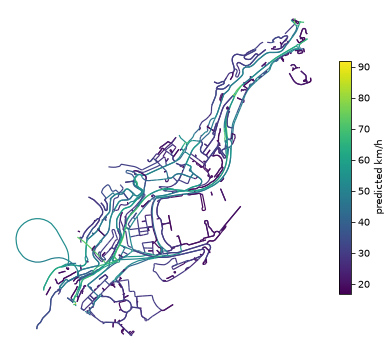

In [7]:
import pandas as pd                                                             # to key the result by edge_id

net.driving.map(color_by=pd.Series(predicted.numpy(), index=turns.edge_id.numpy(), name="predicted km/h"))    # the map

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The main roads, along the coast and through the tunnel loop in the west, have predicted speeds of about 50 to 70 km/h. The small streets have about 20 to 30 km/h. Each color comes from the `edge_id` of its road, so the same Series can join to any other table of the file.

## DGL

[DGL](https://www.dgl.ai) is another graph library for PyTorch. `duckosm.ml.to_dgl` gives a `dgl.DGLGraph` with the
same arrays:

| Where | What |
|---|---|
| `g.ndata["x"]`, `g.edata["edge_attr"]` | the node features and the arc features |
| `g.edata["edge_id"]` (`"nodes"`) or `g.ndata["edge_id"]` (`"turns"`) | the `edge_id` of each arc or node |
| `g.ndata["node_id"]` | the `node_id` of each junction (`"nodes"` only) |

```python
g = duckosm.ml.to_dgl(net.driving, graph="turns", features=["length_m", "lanes", "highway"])   # needs dgl
g.ndata["x"].shape, g.ndata["edge_id"][:3]
```

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> DGL has no wheel on PyPI for the new versions of PyTorch, so the `ml` extra does not install it, and this notebook does not run the call. Install DGL from its own page (dgl.ai) for your version of PyTorch and CUDA. `graph_arrays` gives the same arrays for any other library.

## Try it yourself

**1.** Make the turn graph with `weight="length"` and find the shortest route in metres from `first` to `target`.

<details><summary>Show the answer</summary>

```python
gl = duckosm.ml.to_networkx(net.driving, weight="length")
nx.shortest_path_length(gl, first, target, weight="weight")    # metres, legal turns only
```
</details>

**2.** Find the 5 junctions with the highest betweenness centrality in the junction graph. Use a sample of 300 nodes to make it fast.

<details><summary>Show the answer</summary>

```python
bc = nx.betweenness_centrality(nx.DiGraph(gn), k=300, seed=0)
sorted(bc, key=bc.get, reverse=True)[:5]
```
</details>

**3.** Make the arrays of the turn graph with the features `length_m`, `lanes` and `oneway`, and look at the names of the columns.

<details><summary>Show the answer</summary>

```python
a = duckosm.ml.graph_arrays(net.driving, graph="turns", features=["length_m", "lanes", "oneway"])
a["x_names"], a["x"].shape
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| junction graph | a graph whose nodes are junctions and whose arcs are edges (`graph="nodes"`) |
| turn graph | a graph whose nodes are edges and whose arcs are legal turns (`graph="turns"`) |
| arc | a directed link of a graph, from one node to another |
| feature | a number that describes a node or an arc, as input to a model |
| one-hot column | a 0/1 column for one value of a text column, for example `highway=primary` |
| strongly connected part | a set of nodes where each node can reach each other node |
| tensor | an array of numbers in PyTorch |
| graph convolution (GCN) | a layer that mixes the features of a node with those of its neighbours |
| target | the value that a model learns to predict |

## Summary

| Call | Does |
|---|---|
| `net.driving.to_networkx()`, `duckosm.ml.to_networkx(net, weight="time")` | the turn graph as a `networkx.DiGraph` |
| `duckosm.ml.to_networkx_nodes(net)` | the junction graph as a `networkx.MultiDiGraph`, as OSMnx |
| `net.driving.to_rustworkx()`, `duckosm.ml.to_rustworkx(net, graph="turns", weight="time")` | either graph as a `rustworkx.PyDiGraph`; `attrs["index"]` maps an id to its index |
| `duckosm.ml.graph_arrays(net, graph="nodes", features=...)` | the index and feature arrays, as numpy |
| `duckosm.ml.to_pyg(net, graph="nodes", features=...)` | a PyTorch Geometric `Data` object, with `edge_id` |
| `duckosm.ml.to_dgl(net, graph="nodes", features=...)` | a `dgl.DGLGraph` (needs dgl) |

The reference: [duckosm.ml](../reference/sdk/ml.md), and the page [networkx](../exports/networkx.md).

## The end of the book

This is the last chapter. You can now get and build an area, look inside the file, draw it, join your data by
`edge_id`, fix the OSM data, export the network, find routes, study the street network, use the OSM data in GIS,
simulate traffic, plan transport, make lane maps and train a model on the road graph. Each chapter is in the
[notebook manual](index.md). The [Python SDK reference](../reference/python.md) has every call.